# Course 1 — Kalman Filter Boot Camp

*My study notes, written in simple language. Derivations are skipped — the focus is on ideas, key equations, and small Python demos.*

**Contents**
1. What a Kalman filter does
2. State-space models
3. Describing uncertainty (random variables and noise)
4. The linear Kalman filter — first look

> All code is my own Python rewrite of the ideas (the course itself uses Octave).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

np.random.seed(0)
plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True

---
## 1. What does a Kalman filter do?

A **Kalman filter (KF)** is an algorithm that estimates the **hidden internal state** of a dynamic system using:
- a **mathematical model** of how the system behaves, and
- **noisy sensor measurements**.

**The state** is the smallest set of numbers that summarises the whole past of the system.
If I know the state now and the future inputs, I can predict the future. How the system got here does not matter.
Example: position + velocity of a car.

### Why do we need a model?
We usually cannot measure the full state directly (too expensive, or physically impossible).
So we:
1. run the model forward with the known input → **prediction**,
2. compare the predicted output with the real measured output,
3. use the difference to **correct** the state estimate.

This **predict → correct** loop is the heart of every Kalman filter.

### Two kinds of unknown inputs
| Noise | Meaning |
|---|---|
| Process noise $w_k$ | Unknown disturbances acting on the system (wind, bumps, model errors) |
| Sensor noise $v_k$ | Errors in the measurements |

### Output of a KF
A KF gives two things at every time step:
- the **estimate** $\hat{x}_k$ (best guess of the state),
- the **error covariance** $\Sigma_{\tilde{x},k}$ (how confident the guess is). From it we get **confidence bounds**, e.g. $\pm 3\sigma$.

### Typical applications
- Tracking vehicles and pedestrians (autonomous driving, radar)
- Battery **state of charge (SoC)** and **state of health (SoH)** estimation in EVs
- Navigation: GPS + IMU fusion
- Robotics, aerospace, economics, weather …

### The KF family (roadmap)
| Filter | Used when |
|---|---|
| Linear KF | Linear model, Gaussian noise — optimal |
| Extended KF (EKF) | Nonlinear model, linearised with Jacobians |
| Sigma-point KF (SPKF / UKF / CKF) | Nonlinear model, no derivatives needed, usually more accurate |
| Particle filter | Strongly nonlinear and/or non-Gaussian problems |

---
## 2. State-space models

### Continuous time
$$\dot{x}(t) = A\,x(t) + B\,u(t) + w(t)$$
$$z(t) = C\,x(t) + D\,u(t) + v(t)$$

- $x$ = state, $u$ = known input, $z$ = measured output
- $A$ describes internal dynamics, $B$ how the input enters, $C$ what the sensor sees, $D$ direct feed-through.

### Example tracking models
**Nearly-constant-position (NCP):** object mostly stays still but gets bumped.
State = $[\xi,\ \eta]$ (x and y position), $A = 0$, $C = I$.

**Nearly-constant-velocity (NCV):** object has momentum; velocity changes only slowly due to random forces.
State = $[\xi,\ \dot\xi,\ \eta,\ \dot\eta]$ and
$$A = \begin{bmatrix}0&1&0&0\\0&0&0&0\\0&0&0&1\\0&0&0&0\end{bmatrix},\quad
C = \begin{bmatrix}1&0&0&0\\0&0&1&0\end{bmatrix}$$

**Coordinated-turn:** object moves with constant speed and turn rate $\Omega$. Same state as NCV, but the velocities are coupled through $\Omega$ (they rotate).

### Time response (idea only)
The solution of the state equation is
$$x(t) = e^{At}x(0) + \int_0^t e^{A(t-\tau)}B\,u(\tau)\,d\tau$$
- first term: **natural response** (from the initial state),
- second term: **forced response** (from the input).

$e^{At}$ is the **matrix exponential** — in Python: `scipy.linalg.expm`.

### Converting to discrete time
Computers work in samples. If the input is held constant during one sample period $\Delta t$ (zero-order hold):
$$x_{k+1} = A_d x_k + B_d u_k + w_k,\qquad z_k = C x_k + D u_k + v_k$$
$$A_d = e^{A\Delta t},\qquad B_d = \int_0^{\Delta t} e^{A\tau}d\tau\; B$$

**Handy trick:** compute both at once:
$$\exp\left(\begin{bmatrix}A & B\\ 0 & 0\end{bmatrix}\Delta t\right) = \begin{bmatrix}A_d & B_d\\ 0 & I\end{bmatrix}$$

In [2]:
def c2d(A, B, dt):
    # Zero-order-hold discretisation using the block matrix exponential trick
    n, m = A.shape[0], B.shape[1]
    M = np.zeros((n + m, n + m))
    M[:n, :n], M[:n, n:] = A, B
    Md = expm(M * dt)
    return Md[:n, :n], Md[:n, n:]

# Example system: mass-spring-damper
#   state = [position, velocity],  input = force / mass
m, k_spring, b_damp = 1.0, 1.0, 0.4
A = np.array([[0, 1], [-k_spring/m, -b_damp/m]])
B = np.array([[0], [1]])
C = np.array([[1, 0]])      # we only measure position
D = np.array([[0]])
dt = 0.1

Ad, Bd = c2d(A, B, dt)
print("Ad =\n", Ad.round(4)); print("Bd =\n", Bd.round(4))

Ad =
 [[ 0.9951  0.0979]
 [-0.0979  0.9559]]
Bd =
 [[0.0049]
 [0.0979]]


### Simulating a discrete-time model
Just loop:  `x = Ad @ x + Bd @ u` and `z = C @ x + D @ u`. Below: response to a step force with no noise.

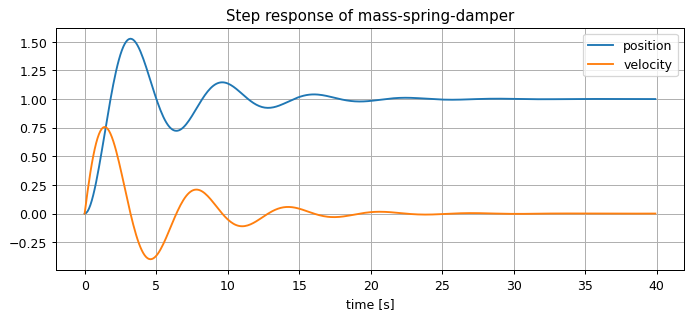

In [3]:
N = 400
t = np.arange(N) * dt
u = np.ones((1, N))            # unit step input
x = np.zeros((2, N))
for k in range(N - 1):
    x[:, k+1] = Ad @ x[:, k] + Bd @ u[:, k]

plt.plot(t, x[0], label="position")
plt.plot(t, x[1], label="velocity")
plt.xlabel("time [s]"); plt.title("Step response of mass-spring-damper"); plt.legend(); plt.show()

### Can a KF even estimate this state? → Observability
A KF can only recover the state if the measurements carry enough information about it.
The system is **observable** if the observability matrix has full rank $n$:
$$\mathcal{O} = \begin{bmatrix} C \\ CA \\ \vdots \\ CA^{n-1}\end{bmatrix}$$
If it is not observable, some state components are invisible to the sensors and the KF cannot fix errors in them.

In [4]:
def is_observable(A, C):
    n = A.shape[0]
    O = np.vstack([C @ np.linalg.matrix_power(A, i) for i in range(n)])
    return np.linalg.matrix_rank(O) == n

print("Measure position :", is_observable(Ad, np.array([[1, 0]])))
print("Measure velocity :", is_observable(Ad, np.array([[0, 1]])))

# A case that is NOT observable: NCV model but we measure only velocities
A_ncv = np.array([[0,1,0,0],[0,0,0,0],[0,0,0,1],[0,0,0,0]])
print("NCV, position sensors:", is_observable(A_ncv, np.array([[1,0,0,0],[0,0,1,0]])))
print("NCV, velocity sensors:", is_observable(A_ncv, np.array([[0,1,0,0],[0,0,0,1]])))

Measure position : True
Measure velocity : True
NCV, position sensors: True
NCV, velocity sensors: False


---
## 3. Describing uncertainty

### Mean and covariance
For a random vector $x$:
- **mean** $\bar{x} = \mathbb{E}[x]$ — the "centre"
- **covariance** $\Sigma_x = \mathbb{E}[(x-\bar x)(x-\bar x)^T]$ — the "spread"
  - diagonal = variances of each element
  - off-diagonal = how elements move together (correlation)

The KF assumes **Gaussian** random variables. A Gaussian is fully described by just its mean and covariance — that is why the KF only needs to track these two things.

### Joint uncertainty
For two variables, the correlation coefficient $\rho = \frac{\sigma_{xy}}{\sigma_x \sigma_y}$ is between −1 and 1.
Samples of a 2-D Gaussian form an **ellipse**-shaped cloud. Positive $\rho$ tilts it upward.

### Simulating correlated Gaussian vectors
1. draw independent standard normals $e \sim \mathcal{N}(0, I)$
2. compute the Cholesky factor $L$ with $LL^T = \Sigma$
3. $x = \bar{x} + L\,e$ has mean $\bar{x}$ and covariance $\Sigma$.

sample mean      : [0.979 1.976]
sample covariance:
 [[1.942 1.166]
 [1.166 0.975]]


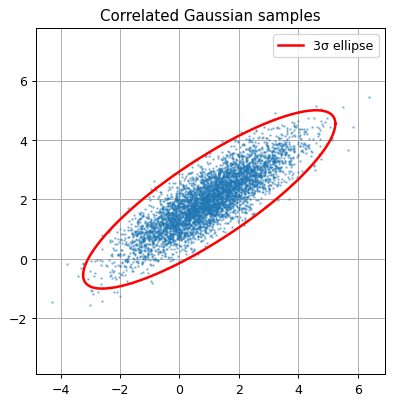

In [5]:
xbar = np.array([1.0, 2.0])
Sigma = np.array([[2.0, 1.2],
                  [1.2, 1.0]])
L = np.linalg.cholesky(Sigma)
samples = xbar[:, None] + L @ np.random.randn(2, 5000)

print("sample mean      :", samples.mean(axis=1).round(3))
print("sample covariance:\n", np.cov(samples).round(3))

# draw the 3-sigma ellipse
th = np.linspace(0, 2*np.pi, 200)
ell = xbar[:, None] + 3 * L @ np.vstack([np.cos(th), np.sin(th)])
plt.figure(figsize=(5, 5))
plt.plot(samples[0], samples[1], '.', ms=2, alpha=0.4)
plt.plot(ell[0], ell[1], 'r', lw=2, label="3σ ellipse")
plt.axis("equal"); plt.legend(); plt.title("Correlated Gaussian samples"); plt.show()

### Time-varying uncertainty — random processes
- A **random process** is a random variable that changes with time.
- **White noise:** values at different times are completely uncorrelated. The KF assumes $w_k$ and $v_k$ are white, zero-mean, Gaussian.
- A process is **stationary** if its statistics do not change with time.

### Dynamic systems with random inputs
For $x_{k+1} = A x_k + B u_k + w_k$ with $w_k \sim \mathcal{N}(0, \Sigma_w)$, mean and covariance propagate as:
$$\bar{x}_{k+1} = A\bar{x}_k + B u_k$$
$$\Sigma_{x,k+1} = A\,\Sigma_{x,k}\,A^T + \Sigma_w$$
This covariance equation is exactly the KF **prediction** step for uncertainty.
For a stable system the covariance settles to a steady value (solution of a Lyapunov equation).

covariance after 300 steps:
 [[ 0.014   -0.00051]
 [-0.00051  0.01426]]
steady-state (Lyapunov)   :
 [[ 0.014   -0.00051]
 [-0.00051  0.01426]]


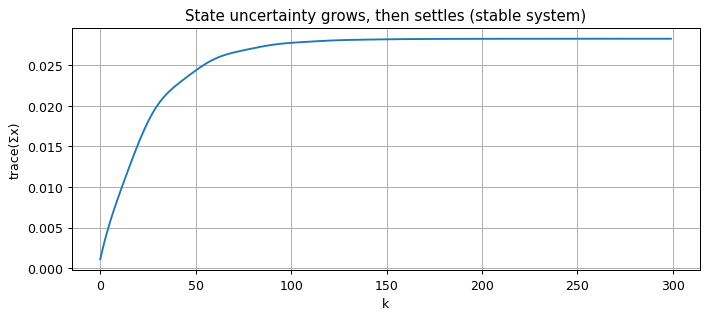

In [6]:
from scipy.linalg import solve_discrete_lyapunov

SigmaW = np.diag([1e-4, 1e-3])
S = np.zeros((2, 2)); trace_hist = []
for k in range(300):
    S = Ad @ S @ Ad.T + SigmaW
    trace_hist.append(np.trace(S))

S_ss = solve_discrete_lyapunov(Ad, SigmaW)
print("covariance after 300 steps:\n", S.round(5))
print("steady-state (Lyapunov)   :\n", S_ss.round(5))

plt.plot(trace_hist); plt.xlabel("k"); plt.ylabel("trace(Σx)")
plt.title("State uncertainty grows, then settles (stable system)"); plt.show()

### Continuous-time noise → discrete-time noise (Van Loan trick)
If the process noise is given in continuous time with spectral density $\Sigma_{\tilde w}$, the matching discrete covariance is
$$\Sigma_w = \int_0^{\Delta t} e^{A\tau}\,\Sigma_{\tilde w}\,e^{A^T\tau}d\tau$$
Instead of integrating, use one matrix exponential:
$$\exp\left(\begin{bmatrix}-A & \Sigma_{\tilde w}\\ 0 & A^T\end{bmatrix}\Delta t\right) = \begin{bmatrix}\cdot & F_{12}\\ 0 & F_{22}\end{bmatrix}
\;\Rightarrow\; A_d = F_{22}^T,\quad \Sigma_w = A_d\,F_{12}$$

In [7]:
def van_loan(A, Qc, dt):
    n = A.shape[0]
    M = np.zeros((2*n, 2*n))
    M[:n, :n], M[:n, n:], M[n:, n:] = -A, Qc, A.T
    F = expm(M * dt)
    Ad = F[n:, n:].T
    Qd = Ad @ F[:n, n:]
    return Ad, Qd

# NCV model in 1-D: state = [position, velocity], random acceleration with density q
A1 = np.array([[0, 1], [0, 0]]); q = 0.5; T = 0.1
Ad1, Qd1 = van_loan(A1, np.array([[0, 0], [0, q]]), T)
print("Qd (Van Loan)  :\n", Qd1)
print("Qd (known formula q*[[T^3/3, T^2/2],[T^2/2, T]]):\n", q*np.array([[T**3/3, T**2/2], [T**2/2, T]]))

Qd (Van Loan)  :
 [[0.00016667 0.0025    ]
 [0.0025     0.05      ]]
Qd (known formula q*[[T^3/3, T^2/2],[T^2/2, T]]):
 [[0.00016667 0.0025    ]
 [0.0025     0.05      ]]


---
## 4. The linear Kalman filter — first look

### Model assumptions
$$x_k = A_{k-1}x_{k-1} + B_{k-1}u_{k-1} + w_{k-1},\qquad z_k = C_k x_k + D_k u_k + v_k$$
$w$ and $v$ are zero-mean, white, Gaussian, uncorrelated with each other, with covariances $\Sigma_{\tilde w}$ and $\Sigma_{\tilde v}$.

### The six steps
**Initialise:** $\hat{x}_0^+$, $\Sigma_{\tilde x,0}^+$

**Step 1 — Predict** (time update)

| | |
|---|---|
| 1a. state prediction | $\hat{x}_k^- = A\hat{x}_{k-1}^+ + B u_{k-1}$ |
| 1b. covariance prediction | $\Sigma_{\tilde x,k}^- = A\Sigma_{\tilde x,k-1}^+A^T + \Sigma_{\tilde w}$ |
| 1c. output prediction | $\hat{z}_k = C\hat{x}_k^- + D u_k$ |

**Step 2 — Correct** (measurement update)

| | |
|---|---|
| 2a. Kalman gain | $L_k = \Sigma_{\tilde x,k}^- C^T\,(C\Sigma_{\tilde x,k}^- C^T + \Sigma_{\tilde v})^{-1}$ |
| 2b. state update | $\hat{x}_k^+ = \hat{x}_k^- + L_k (z_k - \hat{z}_k)$ |
| 2c. covariance update | $\Sigma_{\tilde x,k}^+ = (I - L_kC)\,\Sigma_{\tilde x,k}^-$ |

Superscript $-$ = before seeing the new measurement, $+$ = after.
$z_k - \hat z_k$ is called the **innovation** (the "surprise" in the measurement).

**Intuition for the gain $L$:** if the sensor is very noisy ($\Sigma_{\tilde v}$ large) → $L$ small → trust the model. If the model is uncertain ($\Sigma^-$ large) → $L$ large → trust the sensor.

### Preparing a model
1. Write the continuous-time model, 2. discretise it ($A_d$, $B_d$, and $\Sigma_w$ with Van Loan), 3. choose $\Sigma_v$ from the sensor datasheet, 4. choose the initial estimate and its covariance.

In [8]:
# ---- 1) Simulate the "true" system with noise
N = 1000
t = np.arange(N) * dt
u = np.atleast_2d(np.sin(0.2 * t) + 0.5*np.sign(np.sin(0.05*t)))
SigmaW = np.diag([1e-6, 1e-5])      # process-noise covariance
SigmaV = np.array([[1e-4]])         # sensor-noise covariance (σ = 1 cm)

x = np.zeros((2, N)); z = np.zeros((1, N))
Lw = np.linalg.cholesky(SigmaW)
for k in range(N):
    if k > 0:
        x[:, k] = Ad @ x[:, k-1] + Bd @ u[:, k-1] + Lw @ np.random.randn(2)
    z[:, k] = C @ x[:, k] + D @ u[:, k] + np.sqrt(SigmaV[0, 0]) * np.random.randn()

In [9]:
# ---- 2) Run the Kalman filter
def kalman_filter(z, u, Ad, Bd, C, D, SigmaW, SigmaV, x0, P0, correct=True):
    nx, N = Ad.shape[0], z.shape[1]
    xhat, P = x0.copy(), P0.copy()
    xs, bnd = np.zeros((nx, N)), np.zeros((nx, N))
    xs[:, 0], bnd[:, 0] = xhat, 3*np.sqrt(np.diag(P))
    for k in range(1, N):
        # Step 1: predict
        xhat = Ad @ xhat + Bd @ u[:, k-1]                  # 1a
        P = Ad @ P @ Ad.T + SigmaW                         # 1b
        zhat = C @ xhat + D @ u[:, k]                      # 1c
        if correct:
            # Step 2: correct
            Lk = P @ C.T @ np.linalg.inv(C @ P @ C.T + SigmaV)   # 2a
            xhat = xhat + Lk @ (z[:, k] - zhat)                  # 2b
            P = (np.eye(nx) - Lk @ C) @ P                        # 2c
        xs[:, k], bnd[:, k] = xhat, 3*np.sqrt(np.diag(P))
    return xs, bnd

xhat_kf, bnd_kf = kalman_filter(z, u, Ad, Bd, C, D, SigmaW, SigmaV,
                                x0=np.zeros(2), P0=np.diag([1e-4, 1e-4]))

% of time inside ±3σ bounds: position 100.0%, velocity 99.9%  (theory ≈ 99.7%)


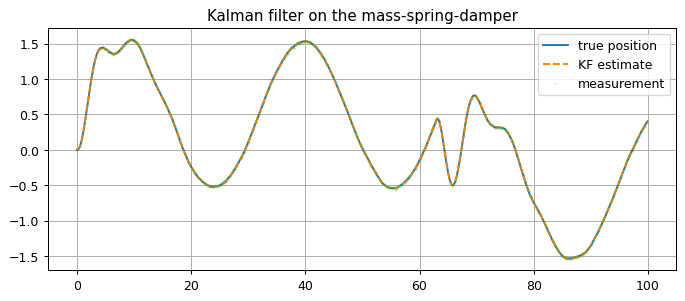

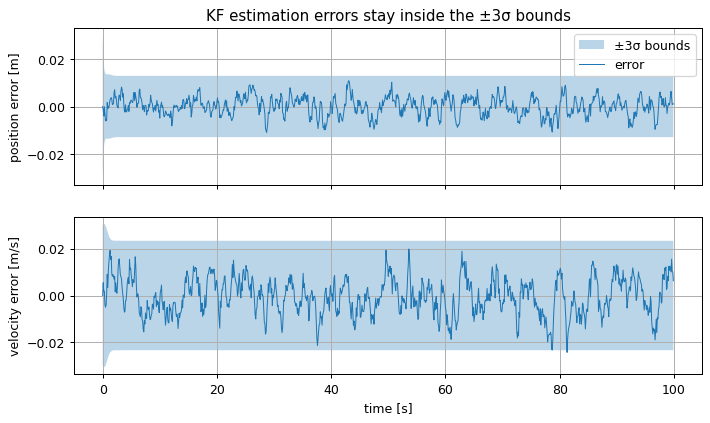

In [10]:
def plot_errors(t, x, xhat, bnd, title):
    fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    names = ["position error [m]", "velocity error [m/s]"]
    for i in range(2):
        ax[i].fill_between(t, -bnd[i], bnd[i], alpha=0.3, label="±3σ bounds")
        ax[i].plot(t, x[i] - xhat[i], lw=0.8, label="error")
        ax[i].set_ylabel(names[i])
    ax[0].legend(loc="upper right"); ax[0].set_title(title); ax[1].set_xlabel("time [s]")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(t, x[0], label="true position"); ax.plot(t, xhat_kf[0], '--', label="KF estimate")
ax.plot(t, z[0], '.', ms=1, alpha=0.3, label="measurement")
ax.legend(); ax.set_title("Kalman filter on the mass-spring-damper")

plot_errors(t, x, xhat_kf, bnd_kf, "KF estimation errors stay inside the ±3σ bounds")
plt.show()

inside = np.mean(np.abs(x - xhat_kf) <= bnd_kf, axis=1) * 100
print(f"% of time inside ±3σ bounds: position {inside[0]:.1f}%, velocity {inside[1]:.1f}%  (theory ≈ 99.7%)")

**What to notice**
- The error never becomes exactly zero (process noise keeps disturbing the system), but it stays small and inside the bounds.
- About 99.7 % of errors should lie inside ±3σ. Much less → the filter is **overconfident** (bad tuning or bad model).

### Comparison: open-loop estimation (no measurement feedback)
If we only run step 1 (prediction), the estimate follows the model but can never correct drift, and the uncertainty keeps growing.

RMS position error  KF: 3.94e-03   open-loop: 1.11e-02


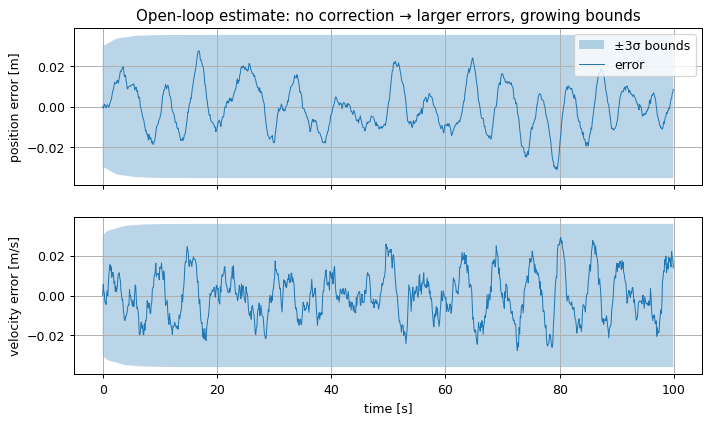

In [11]:
xhat_ol, bnd_ol = kalman_filter(z, u, Ad, Bd, C, D, SigmaW, SigmaV,
                                x0=np.zeros(2), P0=np.diag([1e-4, 1e-4]), correct=False)
plot_errors(t, x, xhat_ol, bnd_ol, "Open-loop estimate: no correction → larger errors, growing bounds")
plt.show()
rms = lambda e: np.sqrt(np.mean(e**2))
print("RMS position error  KF: %.2e   open-loop: %.2e" % (rms(x[0]-xhat_kf[0]), rms(x[0]-xhat_ol[0])))

### Effect of a wrong initial guess
With a bad initial estimate but a honest (large) initial covariance, the KF converges quickly — the measurements pull it back.

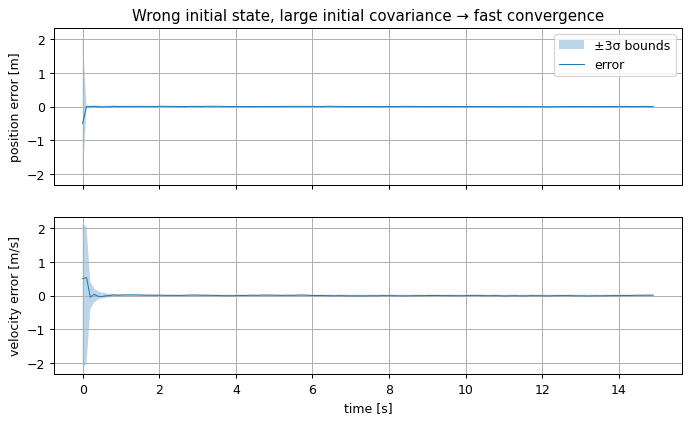

In [12]:
xhat_bad, bnd_bad = kalman_filter(z, u, Ad, Bd, C, D, SigmaW, SigmaV,
                                  x0=np.array([0.5, -0.5]), P0=np.diag([0.5, 0.5]))
plot_errors(t[:150], x[:, :150], xhat_bad[:, :150], bnd_bad[:, :150],
            "Wrong initial state, large initial covariance → fast convergence")
plt.show()

### What can make a Kalman filter fail?
| Cause | Symptom / fix |
|---|---|
| Wrong model ($A$, $B$, $C$ inaccurate) | Biased estimates, errors outside bounds → improve model |
| Wrong noise covariances | Too small $\Sigma_w$: filter ignores measurements and diverges. Too large: noisy estimates |
| Unobservable system | Some states never converge → add sensors |
| Nonlinear system | Linear KF is wrong → use EKF / SPKF (Course 3) |
| Non-Gaussian / non-white noise | Suboptimal → augment the state, or use particle filter (Course 4) |
| Bad initialisation | Too small initial covariance with wrong estimate → slow or no convergence |
| Numerical problems | Covariance loses symmetry / becomes negative → Joseph form, square-root KF (Course 2) |

% inside bounds: position 3.0%, velocity 3.3%


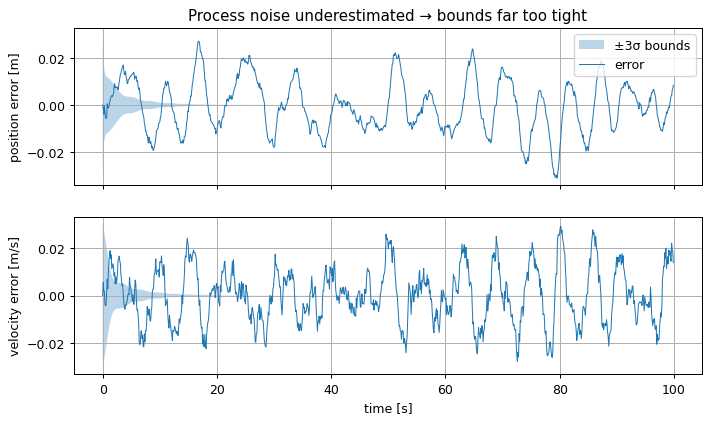

In [13]:
# Example of failure: SigmaW set far too small (filter becomes overconfident)
xhat_f, bnd_f = kalman_filter(z, u, Ad, Bd, C, D, SigmaW*1e-6, SigmaV,
                              x0=np.zeros(2), P0=np.diag([1e-4, 1e-4]))
plot_errors(t, x, xhat_f, bnd_f, "Process noise underestimated → bounds far too tight")
plt.show()
inside = np.mean(np.abs(x - xhat_f) <= bnd_f, axis=1) * 100
print(f"% inside bounds: position {inside[0]:.1f}%, velocity {inside[1]:.1f}%")

---
## Summary
- A KF combines a **model** and **measurements** to estimate a hidden state, with confidence bounds.
- Models are written in **state-space form** and discretised with the matrix exponential.
- Uncertainty is described by **mean and covariance**; for Gaussian variables that is all we need.
- The linear KF is just **six lines** repeated every sample: predict (1a–1c), correct (2a–2c).
- Always check: errors inside ±3σ bounds about 99.7 % of the time.